# **MNIST Model for a Convolution Accelerator**

# 1. Imports and settings

In [ ]:
# 1. Imports and settings
import os, json, random, shutil, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_WORKERS = min(2, os.cpu_count() or 1)
BATCH_SIZE = 64
EPOCHS = 15
TARGET_ACCURACY = 99.5
ARTIFACT_DIR = Path('/content/ai_model_artifacts')
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

print('PyTorch:', torch.__version__)
print('Device :', DEVICE)
print('Output :', ARTIFACT_DIR)


PyTorch: 2.11.0+cu128
Device : cuda
Output : /content/ai_model_artifacts


# 2. MNIST dataset



In [ ]:
# 2. Data preparation
MNIST_MEAN, MNIST_STD = (0.1307,), (0.3081,)

train_transform = transforms.Compose([
    transforms.RandomAffine(degrees=7, translate=(0.08, 0.08), scale=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize(MNIST_MEAN, MNIST_STD),
])
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MNIST_MEAN, MNIST_STD),
])

train_set = datasets.MNIST('/content/data', train=True, download=True, transform=train_transform)
test_set = datasets.MNIST('/content/data', train=False, download=True, transform=test_transform)

loader_args = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                   pin_memory=(DEVICE.type == 'cuda'))
train_loader = DataLoader(train_set, shuffle=True, **loader_args)
test_loader = DataLoader(test_set, shuffle=False, **loader_args)

print(f'Training images: {len(train_set):,}')
print(f'Test images    : {len(test_set):,}')
images, labels = next(iter(test_loader))
print('Batch shape:', tuple(images.shape), '| Labels:', labels[:10].tolist())


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 490kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.68MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.81MB/s]

Training images: 60,000
Test images    : 10,000


Batch shape: (64, 1, 28, 28) | Labels: [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]


# 3. Model

`Conv(1→16) → ReLU → Pool → Conv(16→32) → ReLU → Pool → FC → 10 classes`


In [ ]:
# 3. Model definition
class LeNetInspiredCNN(nn.Module):
    """Main model. Convolution bias is disabled for a clean INT32 reference."""
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1, bias=False)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1, bias=False)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.dropout = nn.Dropout(0.25)
        self.fc2 = nn.Linear(128, 10)

    def forward_features(self, x):
        conv1_out = self.conv1(x)              # 16x28x28
        pool1_out = self.pool(F.relu(conv1_out)) # 16x14x14
        conv2_out = self.conv2(pool1_out)       # 32x14x14
        pool2_out = self.pool(F.relu(conv2_out)) # 32x7x7
        return conv1_out, pool1_out, conv2_out, pool2_out

    def forward(self, x):
        _, _, _, x = self.forward_features(x)
        x = torch.flatten(x, 1)
        x = self.dropout(F.relu(self.fc1(x)))
        return self.fc2(x)


model = LeNetInspiredCNN().to(DEVICE)
with torch.no_grad():
    c1, p1, c2, p2 = model.forward_features(images[:1].to(DEVICE))
print(model)
print('Conv1 output:', tuple(c1.shape), '| Pool1:', tuple(p1.shape))
print('Conv2 output:', tuple(c2.shape), '| Pool2:', tuple(p2.shape))
print('Conv1 learned weights:', model.conv1.weight.numel())
print('Conv2 learned weights:', model.conv2.weight.numel())
print('Total parameters:', sum(p.numel() for p in model.parameters()))


LeNetInspiredCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Conv1 output: (1, 16, 28, 28) | Pool1: (1, 16, 14, 14)
Conv2 output: (1, 32, 14, 14) | Pool2: (1, 32, 7, 7)
Conv1 learned weights: 144
Conv2 learned weights: 4608
Total parameters: 206874


# 4. Training and evaluation

In [ ]:
# 4. Training and evaluation functions
@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    criterion = nn.CrossEntropyLoss()
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        logits = model(x)
        total_loss += criterion(logits, y).item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        total += y.size(0)
    return total_loss / total, 100.0 * correct / total


def train_model(model, train_loader, test_loader, epochs, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)
    history = {'train_loss': [], 'test_loss': [], 'test_acc': []}
    best_acc, best_state = -1.0, None

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        seen = 0
        started = time.time()
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * y.size(0)
            seen += y.size(0)

        scheduler.step()
        test_loss, test_acc = evaluate(model, test_loader)
        train_loss = running_loss / seen
        history['train_loss'].append(train_loss)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)

        if test_acc > best_acc:
            best_acc = test_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        print(f'Epoch {epoch:02d}/{epochs} | train loss {train_loss:.4f} | '
              f'test loss {test_loss:.4f} | test acc {test_acc:.2f}% | '
              f'{time.time()-started:.1f}s')

    model.load_state_dict(best_state)
    return history, best_acc


# 5. Train the LeNet-inspired CNN

Use a T4 GPU in Colab if available. The best checkpoint is saved automatically.


In [ ]:
# 5. Train the model
model = LeNetInspiredCNN().to(DEVICE)
history, float32_accuracy = train_model(model, train_loader, test_loader, epochs=EPOCHS, lr=1e-3)

checkpoint_path = ARTIFACT_DIR / 'lenet_inspired_mnist.pth'
torch.save({
    'model_name': 'LeNet-inspired CNN for MNIST',
    'model_state_dict': model.state_dict(),
    'float32_test_accuracy': float32_accuracy,
    'seed': SEED,
    'normalization': {'mean': MNIST_MEAN, 'std': MNIST_STD},
}, checkpoint_path)

status = 'REACHED' if float32_accuracy >= TARGET_ACCURACY else 'NOT REACHED'
print(f'Float32 accuracy: {float32_accuracy:.2f}% | Target {TARGET_ACCURACY:.2f}%: {status}')
print('Saved:', checkpoint_path)


Epoch 01/15 | train loss 0.3010 | test loss 0.0540 | test acc 98.14% | 23.0s
Epoch 02/15 | train loss 0.1128 | test loss 0.0367 | test acc 98.76% | 20.9s
Epoch 03/15 | train loss 0.0866 | test loss 0.0303 | test acc 98.90% | 20.8s
Epoch 04/15 | train loss 0.0723 | test loss 0.0297 | test acc 98.99% | 22.4s
Epoch 05/15 | train loss 0.0643 | test loss 0.0257 | test acc 99.12% | 20.2s
Epoch 06/15 | train loss 0.0565 | test loss 0.0215 | test acc 99.32% | 22.4s
Epoch 07/15 | train loss 0.0508 | test loss 0.0193 | test acc 99.32% | 22.2s
Epoch 08/15 | train loss 0.0460 | test loss 0.0188 | test acc 99.30% | 21.8s
Epoch 09/15 | train loss 0.0429 | test loss 0.0184 | test acc 99.41% | 21.9s
Epoch 10/15 | train loss 0.0392 | test loss 0.0194 | test acc 99.25% | 21.8s
Epoch 11/15 | train loss 0.0371 | test loss 0.0189 | test acc 99.34% | 21.0s
Epoch 12/15 | train loss 0.0333 | test loss 0.0156 | test acc 99.42% | 22.1s
Epoch 13/15 | train loss 0.0325 | test loss 0.0161 | test acc 99.45% | 22.5s

# 6. Results and learning curves

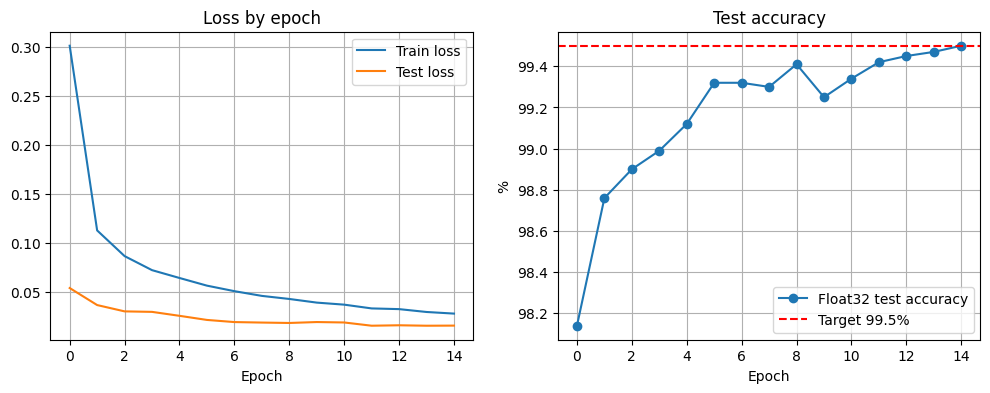

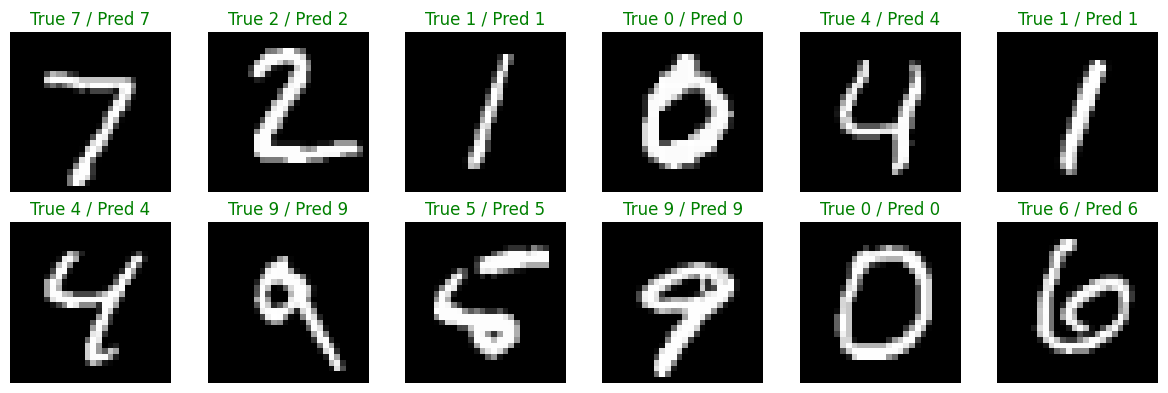

In [ ]:
# 6. Learning curves and sample predictions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history['train_loss'], label='Train loss')
axes[0].plot(history['test_loss'], label='Test loss')
axes[0].set_title('Loss by epoch'); axes[0].set_xlabel('Epoch'); axes[0].grid(True); axes[0].legend()
axes[1].plot(history['test_acc'], marker='o', label='Float32 test accuracy')
axes[1].axhline(TARGET_ACCURACY, color='r', linestyle='--', label='Target 99.5%')
axes[1].set_title('Test accuracy'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('%')
axes[1].grid(True); axes[1].legend()
plt.show()

model.eval()
with torch.inference_mode():
    pred = model(images[:12].to(DEVICE)).argmax(1).cpu()
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for ax, img, y, p in zip(axes.ravel(), images[:12], labels[:12], pred):
    ax.imshow(img.squeeze() * MNIST_STD[0] + MNIST_MEAN[0], cmap='gray')
    ax.set_title(f'True {y.item()} / Pred {p.item()}', color=('green' if y == p else 'red'))
    ax.axis('off')
plt.tight_layout(); plt.show()


# 7. INT8 quantization

Symmetric per-tensor quantization is used: `scale = max(abs(X))/127` and `zero_point = 0`.


In [ ]:
# 7. Quantization helpers and simulated INT8 evaluation
def symmetric_quantize(x):
    max_abs = float(x.detach().abs().max().item())
    scale = max(max_abs / 127.0, 1e-12)
    q = torch.clamp(torch.round(x.detach() / scale), -127, 127).to(torch.int8)
    return q, scale, 0


@torch.inference_mode()
def evaluate_int8_simulated(model, loader):
    model.eval()
    qw1, sw1, _ = symmetric_quantize(model.conv1.weight)
    qw2, sw2, _ = symmetric_quantize(model.conv2.weight)
    qwf1, swf1, _ = symmetric_quantize(model.fc1.weight)
    qwf2, swf2, _ = symmetric_quantize(model.fc2.weight)
    correct = total = 0

    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)

        qx, sx, _ = symmetric_quantize(x)
        x = F.conv2d(qx.float() * sx, qw1.float() * sw1, padding=1)
        x = model.pool(F.relu(x))

        qx, sx, _ = symmetric_quantize(x)
        x = F.conv2d(qx.float() * sx, qw2.float() * sw2, padding=1)
        x = model.pool(F.relu(x)).flatten(1)

        qx, sx, _ = symmetric_quantize(x)
        x = F.relu(F.linear(qx.float() * sx, qwf1.float() * swf1, model.fc1.bias))
        qx, sx, _ = symmetric_quantize(x)
        logits = F.linear(qx.float() * sx, qwf2.float() * swf2, model.fc2.bias)

        correct += (logits.argmax(1) == y).sum().item()
        total += y.size(0)
    return 100.0 * correct / total


int8_accuracy = evaluate_int8_simulated(model, test_loader)
print(f'Float32 Accuracy      : {float32_accuracy:.2f}%')
print(f'INT8 Simulated Acc.   : {int8_accuracy:.2f}%')
print(f'Accuracy drop         : {float32_accuracy - int8_accuracy:.2f} percentage points')


Float32 Accuracy      : 99.50%
INT8 Simulated Acc.   : 99.50%
Accuracy drop         : 0.00 percentage points


# 8. Integer golden model

The reference convolution uses INT8 inputs and weights with an INT32 accumulator.


In [ ]:
# 8. Reference integer convolution (NCHW, no batch dimension)
def golden_conv2d_int32(activation_int8, weight_int8, stride=1, padding=0):
    x = np.asarray(activation_int8, dtype=np.int32)
    w = np.asarray(weight_int8, dtype=np.int32)
    assert x.ndim == 3 and w.ndim == 4
    cin, hin, win = x.shape
    cout, wcin, kh, kw = w.shape
    assert cin == wcin
    xpad = np.pad(x, ((0, 0), (padding, padding), (padding, padding)))
    hout = (hin + 2 * padding - kh) // stride + 1
    wout = (win + 2 * padding - kw) // stride + 1
    out = np.empty((cout, hout, wout), dtype=np.int32)
    for oy in range(hout):
        for ox in range(wout):
            patch = xpad[:, oy*stride:oy*stride+kh, ox*stride:ox*stride+kw]
            out[:, oy, ox] = np.tensordot(
                w, patch, axes=([1, 2, 3], [0, 1, 2])
            ).astype(np.int32)
    return out


def verify_golden(activation_q, weight_q, golden, stride, padding):
    ref = F.conv2d(
        torch.from_numpy(activation_q.astype(np.float32)).unsqueeze(0),
        torch.from_numpy(weight_q.astype(np.float32)),
        stride=stride, padding=padding,
    ).squeeze(0).round().to(torch.int32).numpy()
    np.testing.assert_array_equal(golden, ref)
    return True


# 9. Export Conv1 and Conv2 test vectors

- Conv1: input `1×28×28`, weight `16×1×3×3`, output `16×28×28`
- Conv2: input `16×14×14`, weight `32×16×3×3`, output `32×14×14`


In [ ]:
# 9. Use one correctly classified test image and create the artifacts
model.eval()
sample_x, sample_y = test_set[0]
sample = sample_x.unsqueeze(0).to(DEVICE)
with torch.inference_mode():
    conv1_float, pool1_float, conv2_float, _ = model.forward_features(sample)
    sample_pred = model(sample).argmax(1).item()

print('Sample label/prediction:', sample_y, '/', sample_pred)

layer_specs = {
    'conv1': {
        'activation': sample.squeeze(0).cpu(),
        'weight': model.conv1.weight.detach().cpu(),
        'config': {'input_h': 28, 'input_w': 28, 'cin': 1, 'cout': 16,
                   'kernel': 3, 'stride': 1, 'padding': 1, 'relu': True},
    },
    'conv2': {
        'activation': pool1_float.squeeze(0).cpu(),
        'weight': model.conv2.weight.detach().cpu(),
        'config': {'input_h': 14, 'input_w': 14, 'cin': 16, 'cout': 32,
                   'kernel': 3, 'stride': 1, 'padding': 1, 'relu': True},
    },
}

manifest = {
    'model': 'LeNet-inspired CNN for MNIST',
    'sample_index': 0,
    'sample_label': int(sample_y),
    'sample_prediction': int(sample_pred),
    'float32_test_accuracy_percent': float(float32_accuracy),
    'int8_simulated_test_accuracy_percent': float(int8_accuracy),
    'quantization': 'symmetric per-tensor signed INT8; zero_point=0',
    'accumulator': 'signed INT32',
    'layers': {},
}

for name, spec in layer_specs.items():
    act_f = spec['activation'].numpy().astype(np.float32)
    weight_f = spec['weight'].numpy().astype(np.float32)
    act_q_t, act_scale, act_zp = symmetric_quantize(spec['activation'])
    weight_q_t, weight_scale, weight_zp = symmetric_quantize(spec['weight'])
    act_q = act_q_t.numpy()
    weight_q = weight_q_t.numpy()
    cfg = spec['config']
    golden_conv = golden_conv2d_int32(act_q, weight_q,
                                      stride=cfg['stride'], padding=cfg['padding'])
    golden_relu = np.maximum(golden_conv, 0).astype(np.int32)
    assert verify_golden(act_q, weight_q, golden_conv, cfg['stride'], cfg['padding'])

    np.save(ARTIFACT_DIR / f'{name}_activation_float.npy', act_f)
    np.save(ARTIFACT_DIR / f'{name}_activation_int8.npy', act_q)
    np.save(ARTIFACT_DIR / f'{name}_weight_float.npy', weight_f)
    np.save(ARTIFACT_DIR / f'{name}_weight_int8.npy', weight_q)
    np.save(ARTIFACT_DIR / f'{name}_golden_conv_int32.npy', golden_conv)
    np.save(ARTIFACT_DIR / f'{name}_golden_relu_int32.npy', golden_relu)

    qparams = {
        'activation_scale': act_scale, 'activation_zero_point': act_zp,
        'weight_scale': weight_scale, 'weight_zero_point': weight_zp,
        'output_real_scale': act_scale * weight_scale,
    }
    with open(ARTIFACT_DIR / f'{name}_config.json', 'w') as f:
        json.dump(cfg, f, indent=2)
    with open(ARTIFACT_DIR / f'{name}_quantization_params.json', 'w') as f:
        json.dump(qparams, f, indent=2)

    np.savez_compressed(
        ARTIFACT_DIR / f'{name}_test_vector.npz',
        activation_float=act_f, activation_int8=act_q,
        weight_float=weight_f, weight_int8=weight_q,
        golden_conv_int32=golden_conv, golden_relu_int32=golden_relu,
        activation_scale=np.float32(act_scale), weight_scale=np.float32(weight_scale),
        activation_zero_point=np.int32(act_zp), weight_zero_point=np.int32(weight_zp),
    )
    manifest['layers'][name] = {
        'activation_shape': list(act_q.shape),
        'weight_shape': list(weight_q.shape),
        'golden_output_shape': list(golden_conv.shape),
        'config': cfg,
        'quantization_params': qparams,
        'golden_verified_against_pytorch': True,
    }

with open(ARTIFACT_DIR / 'metrics.json', 'w') as f:
    json.dump({
        'float32_accuracy_percent': float32_accuracy,
        'int8_simulated_accuracy_percent': int8_accuracy,
        'target_accuracy_percent': TARGET_ACCURACY,
        'target_achieved': bool(float32_accuracy >= TARGET_ACCURACY),
    }, f, indent=2)

with open(ARTIFACT_DIR / 'manifest.json', 'w') as f:
    json.dump(manifest, f, indent=2)

print(json.dumps(manifest, indent=2))


Sample label/prediction: 7 / 7
{
  "model": "LeNet-inspired CNN for MNIST",
  "sample_index": 0,
  "sample_label": 7,
  "sample_prediction": 7,
  "float32_test_accuracy_percent": 99.5,
  "int8_simulated_test_accuracy_percent": 99.5,
  "quantization": "symmetric per-tensor signed INT8; zero_point=0",
  "accumulator": "signed INT32",
  "layers": {
    "conv1": {
      "activation_shape": [
        1,
        28,
        28
      ],
      "weight_shape": [
        16,
        1,
        3,
        3
      ],
      "golden_output_shape": [
        16,
        28,
        28
      ],
      "config": {
        "input_h": 28,
        "input_w": 28,
        "cin": 1,
        "cout": 16,
        "kernel": 3,
        "stride": 1,
        "padding": 1,
        "relu": true
      },
      "quantization_params": {
        "activation_scale": 0.02221643079922894,
        "activation_zero_point": 0,
        "weight_scale": 0.005349727127495713,
        "weight_zero_point": 0,
        "output_real_sca

# 10. Verify and package the artifacts

In [ ]:
# 10. Check the output files and create a ZIP archive
required = [
    'lenet_inspired_mnist.pth', 'metrics.json', 'manifest.json',
]
for layer in ('conv1', 'conv2'):
    required += [
        f'{layer}_activation_float.npy', f'{layer}_activation_int8.npy',
        f'{layer}_weight_float.npy', f'{layer}_weight_int8.npy',
        f'{layer}_config.json', f'{layer}_quantization_params.json',
        f'{layer}_golden_conv_int32.npy', f'{layer}_golden_relu_int32.npy',
        f'{layer}_test_vector.npz',
    ]

missing = [name for name in required if not (ARTIFACT_DIR / name).exists()]
assert not missing, f'Missing artifacts: {missing}'

zip_path = shutil.make_archive('/content/mnist_ai_model_artifacts', 'zip', ARTIFACT_DIR)
print(f'Checked {len(required)} artifacts: PASS')
print('ZIP:', zip_path)
for p in sorted(ARTIFACT_DIR.iterdir()):
    print(f'{p.name:42s} {p.stat().st_size:>10,} bytes')


Checked 21 artifacts: PASS
ZIP: /content/mnist_ai_model_artifacts.zip
conv1_activation_float.npy                      3,264 bytes
conv1_activation_int8.npy                         912 bytes
conv1_config.json                                 124 bytes
conv1_golden_conv_int32.npy                    50,304 bytes
conv1_golden_relu_int32.npy                    50,304 bytes
conv1_quantization_params.json                    188 bytes
conv1_test_vector.npz                          20,529 bytes
conv1_weight_float.npy                            704 bytes
conv1_weight_int8.npy                             272 bytes
conv2_activation_float.npy                     12,672 bytes
conv2_activation_int8.npy                       3,264 bytes
conv2_config.json                                 125 bytes
conv2_golden_conv_int32.npy                    25,216 bytes
conv2_golden_relu_int32.npy                    25,216 bytes
conv2_quantization_params.json                    188 bytes
conv2_test_vector.npz         

# 11. Download the results

This cell automatically downloads the ZIP file after the previous steps have completed.


In [ ]:
# 11. Download the ZIP file automatically
from google.colab import files

download_path = '/content/mnist_ai_model_artifacts.zip'
assert Path(download_path).exists(), 'ZIP file not found. Run section 10 first.'
print('Downloading:', download_path)
files.download(download_path)


Downloading: /content/mnist_ai_model_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 12. Result summary

In [ ]:
# 12. Show the final results
with open(ARTIFACT_DIR / 'metrics.json') as f:
    final_metrics = json.load(f)

print('Model                 : LeNet-inspired CNN for MNIST')
print(f"Float32 accuracy      : {final_metrics['float32_accuracy_percent']:.2f}%")
print(f"INT8 simulated acc.   : {final_metrics['int8_simulated_accuracy_percent']:.2f}%")
print(f"Target achieved       : {final_metrics['target_achieved']}")
print('Model checkpoint       :', ARTIFACT_DIR / 'lenet_inspired_mnist.pth')
print('Hardware test vectors :', '/content/mnist_ai_model_artifacts.zip')


Model                 : LeNet-inspired CNN for MNIST
Float32 accuracy      : 99.50%
INT8 simulated acc.   : 99.50%
Target achieved       : True
Model checkpoint       : /content/ai_model_artifacts/lenet_inspired_mnist.pth
Hardware test vectors : /content/mnist_ai_model_artifacts.zip


# **13. Export FPGA-ready artifact bundle**

This section is self-contained and uses the files already generated in ARTIFACT_DIR. It replaces the old cells that imported missing export_conv1_real_vectors.py / export_conv2_real_vectors.py modules.

In [ ]:
# 13. Create and download a clean FPGA artifact ZIP
from pathlib import Path
import shutil
from google.colab import files

src_dir = Path(ARTIFACT_DIR)
fpga_dir = Path('/content/FPGA_model_data')

if fpga_dir.exists():
    shutil.rmtree(fpga_dir)
fpga_dir.mkdir(parents=True, exist_ok=True)

# Copy every generated artifact from the validated model-export directory.
for p in src_dir.iterdir():
    if p.is_file():
        shutil.copy2(p, fpga_dir / p.name)

required = [
    'conv1_activation_int8.npy',
    'conv1_weight_int8.npy',
    'conv1_golden_conv_int32.npy',
    'conv2_activation_int8.npy',
    'conv2_weight_int8.npy',
    'conv2_golden_conv_int32.npy',
    'lenet_inspired_mnist.pth',
]
missing = [name for name in required if not (fpga_dir / name).exists()]
assert not missing, f'Missing required FPGA artifacts: {missing}. Run Sections 1–10 first.'

zip_path = shutil.make_archive('/content/FPGA_model_data', 'zip', fpga_dir)
print('FPGA artifact bundle created successfully')
print('Folder:', fpga_dir)
print('ZIP   :', zip_path)
print('Files :', len(list(fpga_dir.iterdir())))

files.download(zip_path)


FPGA artifact bundle created successfully
Folder: /content/FPGA_model_data
ZIP   : /content/FPGA_model_data.zip
Files : 21


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>